In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import requests
import zipfile
import io
from pathlib import Path

Matplotlib is building the font cache; this may take a moment.


In [12]:
base_dir = Path.cwd().parent  
# Path(__file__).resolve().parent in .py


downloading, extracting and savingn MEF income data

In [ ]:
# Only the year changes in the MEF download link, so we keep one template
# and fill in the year with .format(year=...). No long URL is repeated.
MEF_URL_TEMPLATE = (
    "https://www1.finanze.gov.it/finanze/analisi_stat/public/v_4_0_0/contenuti/"
    "Redditi_e_principali_variabili_IRPEF_su_base_comunale_CSV_{year}.zip?d=1615465800"
)

INCOME_YEARS = [2014, 2024]

mef_raw_data_dir = base_dir / "data" / "raw" / "mef"

# Create the 'data/raw/mef' directory if it doesn't already exist
mef_raw_data_dir.mkdir(parents=True, exist_ok=True)

# File types we accept from inside the ZIP (a tuple, because endswith() accepts tuples)
extensions = (".csv", ".xlsx", ".xls")

for year in INCOME_YEARS:
    url = MEF_URL_TEMPLATE.format(year=year)

    # Cache: if a file for this year is already on disk, skip the download.
    # mef_raw_data_dir / "..." is already a Path, so no need to wrap it in Path().
    if any((mef_raw_data_dir / f"mef_income_{year}{ext}").exists() for ext in extensions):
        print(f"mef_income_{year} already downloaded, skipping.")
        continue

    print(f"Downloading {year} from {url} ...")
    # timeout=30: give up after 30 seconds instead of freezing forever
    response = requests.get(url, timeout=30)
    # turn HTTP errors (404, 500, ...) into exceptions
    response.raise_for_status()

    # Open the ZIP directly from memory (no temporary .zip file on disk)
    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        # .lower() so that "DATA.CSV" is accepted too, not only "data.csv"
        data_files = [
            info for info in z.infolist()
            if info.filename.lower().endswith(extensions)
        ]

        # We save every file as "mef_income_<year>.<ext>". With two data files
        # in one ZIP, the second would overwrite the first, so we stop and say so.
        if len(data_files) != 1:
            raise ValueError(
                f"Expected 1 data file in the {year} ZIP, found {len(data_files)}: "
                f"{[info.filename for info in data_files]}"
            )

        fileinfo = data_files[0]
        extension = Path(fileinfo.filename).suffix.lower()
        target_path = mef_raw_data_dir / f"mef_income_{year}{extension}"

        # Read the file out of the ZIP and write it to disk
        target_path.write_bytes(z.read(fileinfo.filename))
        print(f"Extracted to: {target_path}")

Extracted to: /Users/armanfayyazi/Desktop/Folders/unimi/coding/project/housing-affordability-italy/data/raw/mef/mef_income_2014.csv
Extracted to: /Users/armanfayyazi/Desktop/Folders/unimi/coding/project/housing-affordability-italy/data/raw/mef/mef_income_2024.csv


In [41]:
mef_dfs = {}
for year in INCOME_YEARS:
    existing_file = next(
        (mef_raw_data_dir/f"mef_income_{year}{ext}" for ext in extensions
        if (mef_raw_data_dir/f"mef_income_{year}{ext}").exists()),
        None
    )

    if not existing_file:
        print(f"Warning: No data file found for {year} in {mef_raw_data_dir}")
        continue

    print(f"Loading {existing_file.name} into pandas...")

    if existing_file.suffix == ".csv":
        df = pd.read_csv(
                        existing_file,
                        sep=";",
                        encoding="latin-1",
                        dtype={"Codice Istat Comune": str},
                        keep_default_na=False,   # don't treat "NA", "N/A", "null"... as missing, since napoli province is NA
                        na_values=[""],          # only an empty cell is missing
                    )
    else:
        df = pd.read_excel(existing_file)


    df['year'] = year

    mef_dfs[year] = df

Loading mef_income_2014.csv into pandas...
Loading mef_income_2024.csv into pandas...


In [42]:
df2014 = mef_dfs[2014]
df2014.head(10)

,Anno di imposta,Codice catastale,Codice Istat Comune,Denominazione Comune,Sigla Provincia,Regione,Codice Istat Regione,Numero contribuenti,Reddito da fabbricati - Frequenza,Reddito da fabbricati - Ammontare,...,Reddito complessivo da 15000 a 26000 euro - Ammontare,Reddito complessivo da 26000 a 55000 euro - Frequenza,Reddito complessivo da 26000 a 55000 euro - Ammontare,Reddito complessivo da 55000 a 75000 euro - Frequenza,Reddito complessivo da 55000 a 75000 euro - Ammontare,Reddito complessivo da 75000 a 120000 euro - Frequenza,Reddito complessivo da 75000 a 120000 euro - Ammontare,Reddito complessivo oltre 120000 euro - Frequenza,Reddito complessivo oltre 120000 euro - Ammontare,year
0,2014,A001,028001,ABANO TERME,PD,Veneto,5,14173,6977.0,11684674.0,...,98874364,2889.0,101381179.0,399.0,25555498.0,366.0,33642305.0,156.0,30814993.0,2014
1,2014,A004,098001,ABBADIA CERRETO,LO,Lombardia,3,212,89.0,70008.0,...,1669369,35.0,1128384.0,NaN,NaN,0.0,0.0,0.0,0.0,2014
2,2014,A005,097001,ABBADIA LARIANA,LC,Lombardia,3,2384,1187.0,1565868.0,...,17631595,584.0,19953253.0,60.0,3781730.0,43.0,3910776.0,20.0,4110091.0,2014
3,2014,A006,052001,ABBADIA SAN SALVATORE,SI,Toscana,9,4936,2602.0,3327596.0,...,34555118,718.0,24203466.0,56.0,3568341.0,29.0,2605800.0,11.0,1812778.0,2014
4,2014,A007,095001,ABBASANTA,OR,Sardegna,20,1755,853.0,777290.0,...,10090801,411.0,13455623.0,21.0,1363203.0,8.0,726624.0,NaN,NaN,2014
5,2014,A008,068001,ABBATEGGIO,PE,Abruzzo,13,289,122.0,75154.0,...,1570478,26.0,840483.0,NaN,NaN,0.0,0.0,0.0,0.0,2014
6,2014,A010,015002,ABBIATEGRASSO,MI,Lombardia,3,22731,11217.0,17402757.0,...,164513830,5561.0,191169405.0,645.0,40603241.0,408.0,37665279.0,155.0,31363478.0,2014
7,2014,A012,047001,ABETONE,PT,Toscana,9,533,223.0,395804.0,...,3295526,56.0,1756826.0,5.0,328710.0,NaN,NaN,NaN,NaN,2014
8,2014,A013,076001,ABRIOLA,PZ,Basilicata,17,1030,319.0,178759.0,...,4570426,56.0,1865787.0,5.0,334658.0,NaN,NaN,0.0,0.0,2014
9,2014,A014,088001,ACATE,RG,Sicilia,19,6834,2112.0,1554967.0,...,16917451,344.0,11310094.0,21.0,1330499.0,14.0,1329985.0,4.0,604104.0,2014


In [43]:
df2014["Codice Istat Comune"].str.contains("Ã").sum()

# The result is zero. MEF names are uppercase ASCII; use ISTAT names for display

np.int64(0)

In [44]:
df2014.dtypes

Anno di imposta                                                                                                     int64
Codice catastale                                                                                                      str
Codice Istat Comune                                                                                                   str
Denominazione Comune                                                                                                  str
Sigla Provincia                                                                                                       str
Regione                                                                                                               str
Codice Istat Regione                                                                                                int64
Numero contribuenti                                                                                                 int64
Reddito da fabbricati - 

In [46]:
CODE_COL = "Codice Istat Comune"
PROVINCE_COL = "Sigla Provincia"
NAME_COL = "Denominazione Comune"
TAXPAYERS_COL = "Numero contribuenti"
TAXABLE_FREQ_COL = "Reddito imponibile - Frequenza"
TAXABLE_AMOUNT_COL = "Reddito imponibile - Ammontare"
MILAN_CODE = "015146"

### 1. Same checks on every year + column differences


In [48]:
for year, df in mef_dfs.items():
    print(f"===== {year} =====")
    print("shape:", df.shape)
    print("code column type:", df[CODE_COL].dtype)
    print("example codes:", df[CODE_COL].head(3).tolist())   # leading zero still there?
    # Missing values: only show the columns that have some
    missing = df.isna().sum()
    print("columns with NaN:")
    print(missing[missing > 0].sort_values(ascending=False))
    print()

# Symmetric difference (^): columns that exist in ONE of the two years only
cols_2014 = set(mef_dfs[2014].columns)
cols_2024 = set(mef_dfs[2024].columns)
print("Only in 2014:", sorted(cols_2014 - cols_2024))
print("Only in 2024:", sorted(cols_2024 - cols_2014))

===== 2014 =====
shape: (8049, 49)
code column type: str
example codes: ['028001', '098001', '097001']
columns with NaN:
Reddito complessivo oltre 120000 euro - Ammontare                                                                 2304
Reddito complessivo oltre 120000 euro - Frequenza                                                                 2304
Reddito di spettanza dell'imprenditore in contabilita' ordinaria  (comprensivo dei valori nulli) - Ammontare      1976
Reddito di spettanza dell'imprenditore in contabilita' ordinaria  (comprensivo dei valori nulli) - Frequenza      1976
Reddito complessivo minore di zero euro - Frequenza                                                               1889
Reddito complessivo minore di zero euro - Ammontare                                                               1889
Reddito complessivo da 75000 a 120000 euro - Ammontare                                                            1476
Reddito complessivo da 75000 a 120000 euro - F

### 1b. Make the two years comparable

What check 1 showed:
 - 2024 says "- Ammontare in euro", 2014 says "- Ammontare" (one even has a trailing space: "oltre 120000 euro - Ammontare ").
 - Some names contain double spaces ("partecipazione  (comprensivo...").
 - The lowest bracket was renamed: "minore di zero" (2014) became "minore o uguale a zero" (2024). It now also includes people with exactly 0.
 - 2024 has a column called " " that is empty in every row: each line of the CSV ends with ";", so pandas sees one extra, empty column.
 - "Sigla Provincia" has 92 NaN in both years: Napoli's code is "NA", and pandas reads the text "NA" as a missing value! (Napoli province has exactly 92 comuni.)

 Fix for the province: re-read the CSVs with
     pd.read_csv(..., keep_default_na=False, na_values=[""])
 which means: "only an empty cell is missing, NA is just text".

In [49]:
def clean_mef_columns(df):
    """
    Give the MEF columns the same names in every year and drop empty columns.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table as read from the CSV.

    Returns
    -------
    pandas.DataFrame
        A copy with harmonised column names and without all-empty columns.
    """
    df = df.copy()
    # " ".join(name.split()) removes leading/trailing spaces AND turns double
    # spaces into single ones
    df.columns = [" ".join(col.split()) for col in df.columns]
    df.columns = [
        col.replace("- Ammontare in euro", "- Ammontare")
           .replace("minore o uguale a zero", "minore di zero")
        for col in df.columns
    ]
    # Drop columns where every value is missing (the empty " " column)
    return df.dropna(axis=1, how="all")


mef_dfs = {year: clean_mef_columns(df) for year, df in mef_dfs.items()}

cols_2014 = set(mef_dfs[2014].columns)
cols_2024 = set(mef_dfs[2024].columns)
print("Only in 2014:", sorted(cols_2014 - cols_2024))
print("Only in 2024:", sorted(cols_2024 - cols_2014))
print("Napoli province rows:", (mef_dfs[2024][PROVINCE_COL] == "NA").sum())   # 92 after the re-read

Only in 2014: []
Only in 2024: ['Reddito complessivo - Ammontare', 'Reddito complessivo - Frequenza', 'Trattamento spettante - Ammontare', 'Trattamento spettante - Frequenza']
Napoli province rows: 92


### 2. Is each comune in the file only once?

In [50]:
for year, df in mef_dfs.items():
    unique = df[CODE_COL].is_unique
    print(f"{year}: codes unique = {unique}")
    if not unique:
        # keep=False marks ALL copies of a duplicated code, so we see every one
        duplicates = df[df[CODE_COL].duplicated(keep=False)]
        print(duplicates[[CODE_COL, NAME_COL]].sort_values(CODE_COL))

2014: codes unique = True
2024: codes unique = True


### 3. Average taxable income per comune
mean income = total taxable income / number of people with taxable income

In [51]:
for year, df in mef_dfs.items():
    df["mean_income"] = df[TAXABLE_AMOUNT_COL] / df[TAXABLE_FREQ_COL]

    print(f"===== {year} =====")
    print(df["mean_income"].describe().round(0))

    columns_to_show = [CODE_COL, NAME_COL, TAXPAYERS_COL, "mean_income"]
    print("\n5 lowest:")
    print(df.nsmallest(5, "mean_income")[columns_to_show])
    print("\n5 highest:")
    print(df.nlargest(5, "mean_income")[columns_to_show])
    print("\nMilan:")
    print(df.loc[df[CODE_COL] == MILAN_CODE, columns_to_show])
    print()

# Look at the size of the extreme comuni: are they tiny villages?
# A village with 50 taxpayers can have a strange average because of 1-2 people.

===== 2014 =====
count     8049.0
mean     17143.0
std       3609.0
min       3260.0
25%      14380.0
50%      17281.0
75%      19625.0
max      44514.0
Name: mean_income, dtype: float64

5 lowest:
     Codice Istat Comune Denominazione Comune  Numero contribuenti  \
8048                   0         Non indicato                 3418   
1877              013062             CAVARGNA                  123   
5680              013233            VAL REZZO                   92   
2519              103027       CURSOLO-ORASSO                   92   
3342              103036                GURRO                  173   

      mean_income  
8048  3259.764775  
1877  6579.230769  
5680  6922.083333  
2519  7309.247059  
3342  7548.794872  

5 highest:
     Codice Istat Comune Denominazione Comune  Numero contribuenti  \
570               015015             BASIGLIO                 5257   
2523              015097               CUSAGO                 2716   
447               018006         BADIA 

### 4. Row counts: how many comuni disappeared between 2014 and 2024?

In [52]:
codes_2014 = set(mef_dfs[2014][CODE_COL])
codes_2024 = set(mef_dfs[2024][CODE_COL])

print("rows 2014:", len(mef_dfs[2014]))
print("rows 2024:", len(mef_dfs[2024]))
print("codes in 2014 but not in 2024 (merged or renamed):", len(codes_2014 - codes_2024))
print("codes in 2024 but not in 2014 (new comuni):", len(codes_2024 - codes_2014))

# A few examples of comuni that no longer exist
gone = mef_dfs[2014][mef_dfs[2014][CODE_COL].isin(codes_2014 - codes_2024)]
print(gone[[CODE_COL, NAME_COL, PROVINCE_COL]].head(10))

rows 2014: 8049
rows 2024: 7897
codes in 2014 but not in 2024 (merged or renamed): 401
codes in 2024 but not in 2014 (new comuni): 249
    Codice Istat Comune Denominazione Comune Sigla Provincia
7                047001              ABETONE              PT
24               043001          ACQUACANINA              MC
33               075001   ACQUARICA DEL CAPO              LE
57               104001               AGGIUS              OT
94               104003       ALA' DEI SARDI              OT
100              025002       ALANO DI PIAVE              BL
112              018002   ALBAREDO ARNABOLDI              PV
162              001005      ALICE SUPERIORE              TO
173              006006    ALLUVIONI CAMBIO'              AL
215              022004               AMBLAR              TN


### 5. Findings (fill in by hand)

| File | Separator | Encoding | Rows 2014 / 2024 | One row = ... | Key column | Columns I need |
|---|---|---|---|---|---|---|
| MEF | `;` | latin-1 | ... / ... | one comune in one tax year | Codice Istat Comune (text, 6 digits) | Reddito imponibile Freq/Amm, lavoro dipendente Freq/Amm, ... |

Notes:
- Names are uppercase ASCII (`CAVAGLIA'`): display the ISTAT names instead.
- NaN = value hidden because very few taxpayers (privacy), mostly in small comuni.
- No "reddito complessivo" total: I use reddito imponibile as the income measure.
- ... comuni in 2014 have no match in 2024 -> code harmonisation in Week 3.

## MEF: first charts

Two kinds of charts:
- **Bar charts for ONE comune**: compare categories (types of income, brackets)
  for the comune you choose, next to Italy as a reference.
- **Histograms across ALL comuni**: show how a value (e.g. mean income) is
  distributed over the ~7,900 comuni.

The functions below are written so that you can later move them into
affordability/plots.py and reuse them in the Streamlit app.

In [53]:
# Short labels -> a piece of text that appears in exactly one MEF column name.
# Searching by keyword avoids typing the very long names (with double spaces!).
INCOME_TYPES = {
    "Employees": "lavoro dipendente",
    "Pensioners": "pensione",
    "Buildings": "fabbricati",
    "Self-employed": "lavoro autonomo",
    "Business (ordinary)": "contabilita' ordinaria",
    "Business (simplified)": "contabilita' semplificata",
    "Partnerships": "partecipazione",
}

INCOME_BRACKETS = {
    "< 0": "minore di zero",
    "0-10k": "da 0 a 10000",
    "10-15k": "da 10000 a 15000",
    "15-26k": "da 15000 a 26000",
    "26-55k": "da 26000 a 55000",
    "55-75k": "da 55000 a 75000",
    "75-120k": "da 75000 a 120000",
    "> 120k": "oltre 120000",
}

def find_column(df, keyword, kind):
    """
    Find the MEF column that contains a keyword and ends with a given kind.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table.
    keyword : str
        Text that appears in the column name, e.g. ``"pensione"``.
    kind : str
        ``"Frequenza"`` (number of taxpayers) or ``"Ammontare"`` (euros).

    Returns
    -------
    str
        The full column name.

    Raises
    ------
    KeyError
        If no column, or more than one column, matches.
    """
    matches = [
        col for col in df.columns
        if keyword in col and col.endswith(f"- {kind}")
    ]
    if len(matches) != 1:
        raise KeyError(f"Expected 1 column for '{keyword}' / {kind}, found {matches}")
    return matches[0]


def category_table(df, categories):
    """
    Build a table with the number of taxpayers and the euros for each category.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table (all comuni, or just one row).
    categories : dict
        Mapping ``label -> keyword``, e.g. ``INCOME_TYPES``.

    Returns
    -------
    pandas.DataFrame
        Index = labels; columns ``taxpayers`` and ``amount``, summed over the
        rows of ``df``. Hidden values (NaN) are counted as 0.
    """
    rows = {}
    for label, keyword in categories.items():
        freq_col = find_column(df, keyword, "Frequenza")
        amount_col = find_column(df, keyword, "Ammontare")
        rows[label] = {
            "taxpayers": df[freq_col].fillna(0).sum(),
            "amount": df[amount_col].fillna(0).sum(),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def comune_row(df, comune):
    """
    Select one comune by ISTAT code or by (part of) its name.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table.
    comune : str
        A 6-digit ISTAT code (``"015146"``) or a name (``"MILANO"``).

    Returns
    -------
    pandas.DataFrame
        A one-row table.

    Raises
    ------
    ValueError
        If no comune, or more than one, matches.
    """
    if comune.isdigit():
        selected = df[df[CODE_COL] == comune.zfill(6)]
    else:
        selected = df[df[NAME_COL] == comune.upper()]
    if len(selected) != 1:
        raise ValueError(f"'{comune}' matches {len(selected)} comuni")
    return selected


In [54]:
def plot_income_types(df, comune):
    """
    Compare the types of income of one comune with Italy as a whole.

    Left panel: share of taxpayers who have each type of income.
    Right panel: average euros per taxpayer who has it.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table for one year (all comuni).
    comune : str
        ISTAT code or name of the comune.

    Returns
    -------
    matplotlib.figure.Figure
    """
    row = comune_row(df, comune)
    local = category_table(row, INCOME_TYPES)
    italy = category_table(df, INCOME_TYPES)

    # Share of taxpayers with that income (one person can have more than one type,
    # e.g. a pension AND a rented flat, so the shares don't add up to 100%)
    local_share = local["taxpayers"] / row[TAXPAYERS_COL].iloc[0] * 100
    italy_share = italy["taxpayers"] / df[TAXPAYERS_COL].sum() * 100

    # Average euros per person WITH that income (Ammontare / Frequenza).
    # replace(0, nan) avoids dividing by zero when nobody has that income.
    local_avg = local["amount"] / local["taxpayers"].replace(0, np.nan)
    italy_avg = italy["amount"] / italy["taxpayers"].replace(0, np.nan)

    name = row[NAME_COL].iloc[0]
    positions = np.arange(len(INCOME_TYPES))
    width = 0.4

    fig, (ax_share, ax_avg) = plt.subplots(1, 2, figsize=(13, 5))

    ax_share.barh(positions - width / 2, local_share, width, label=name)
    ax_share.barh(positions + width / 2, italy_share, width, label="Italy", color="lightgray")
    ax_share.set_yticks(positions, INCOME_TYPES.keys())
    ax_share.set_xlabel("% of taxpayers with this income")
    ax_share.set_title("Who earns what")
    ax_share.legend()
    ax_share.invert_yaxis()   # first category at the top

    ax_avg.barh(positions - width / 2, local_avg / 1000, width, label=name)
    ax_avg.barh(positions + width / 2, italy_avg / 1000, width, label="Italy", color="lightgray")
    ax_avg.set_yticks(positions, INCOME_TYPES.keys())
    ax_avg.set_xlabel("Average income per person who has it (thousand €)")
    ax_avg.set_title("How much they earn")
    ax_avg.invert_yaxis()

    year = int(row["Anno di imposta"].iloc[0])
    fig.suptitle(f"{name}: income by type, tax year {year}  (source: MEF)")
    fig.tight_layout()
    return fig


def plot_income_brackets(df, comune):
    """
    Show how the taxpayers of one comune are spread across income brackets,
    compared with Italy.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table for one year (all comuni).
    comune : str
        ISTAT code or name of the comune.

    Returns
    -------
    matplotlib.figure.Figure
    """
    row = comune_row(df, comune)
    local = category_table(row, INCOME_BRACKETS)["taxpayers"]
    italy = category_table(df, INCOME_BRACKETS)["taxpayers"]

    # Percentages, so a small village and Italy can be compared
    local_pct = local / local.sum() * 100
    italy_pct = italy / italy.sum() * 100

    name = row[NAME_COL].iloc[0]
    positions = np.arange(len(INCOME_BRACKETS))
    width = 0.4

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(positions - width / 2, local_pct, width, label=name)
    ax.bar(positions + width / 2, italy_pct, width, label="Italy", color="lightgray")
    ax.set_xticks(positions, INCOME_BRACKETS.keys())
    ax.set_xlabel("Total income bracket (€ per year)")
    ax.set_ylabel("% of taxpayers")
    ax.set_title(f"{name}: taxpayers by income bracket  (source: MEF)")
    ax.legend()
    fig.tight_layout()
    return fig


def plot_mean_income_histogram(df, highlight=None, min_taxpayers=0):
    """
    Histogram of the average taxable income across all comuni.

    Parameters
    ----------
    df : pandas.DataFrame
        A MEF income table with a ``mean_income`` column.
    highlight : str, optional
        ISTAT code or name of a comune to mark with a vertical line.
    min_taxpayers : int, optional
        Ignore comuni with fewer taxpayers than this (tiny villages are noisy).

    Returns
    -------
    matplotlib.figure.Figure
    """
    data = df[df[TAXPAYERS_COL] >= min_taxpayers]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(data["mean_income"] / 1000, bins=60, color="steelblue", edgecolor="white")
    median = data["mean_income"].median() / 1000
    ax.axvline(median, color="black", linestyle="--", label=f"Median comune: {median:.1f}k €")

    if highlight is not None:
        row = comune_row(df, highlight)
        value = row["mean_income"].iloc[0] / 1000
        ax.axvline(value, color="crimson", label=f"{row[NAME_COL].iloc[0]}: {value:.1f}k €")

    ax.set_xlabel("Average taxable income per taxpayer (thousand €)")
    ax.set_ylabel("Number of comuni")
    ax.set_title(f"Average income across {len(data):,} comuni  (source: MEF)")
    ax.legend()
    fig.tight_layout()
    return fig


### Try the charts
Change the comune and the year, and look at what changes.

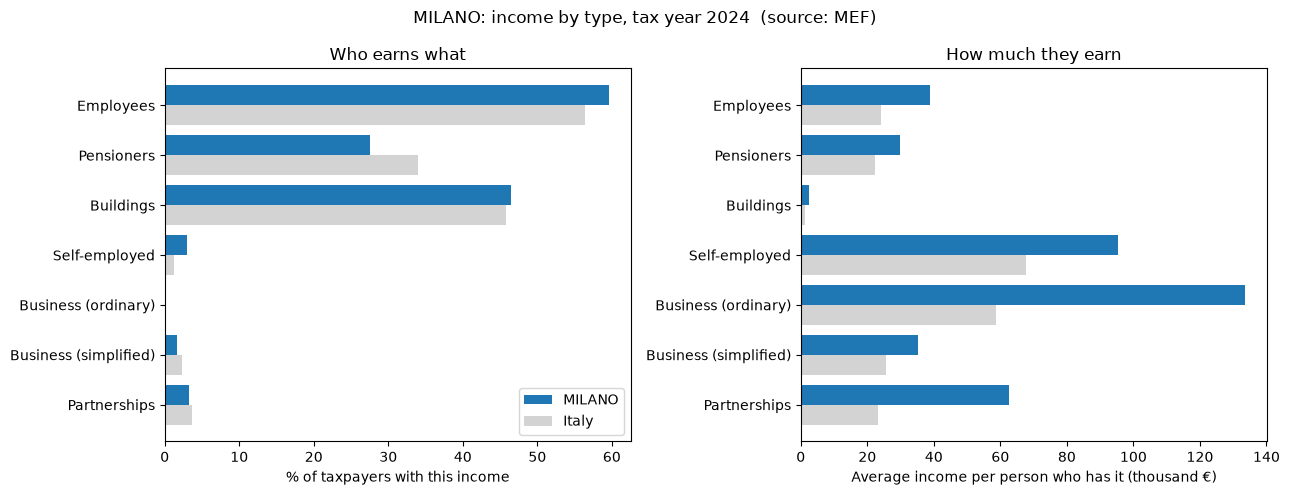

In [55]:
plot_income_types(mef_dfs[2024], "MILANO")
plt.show()

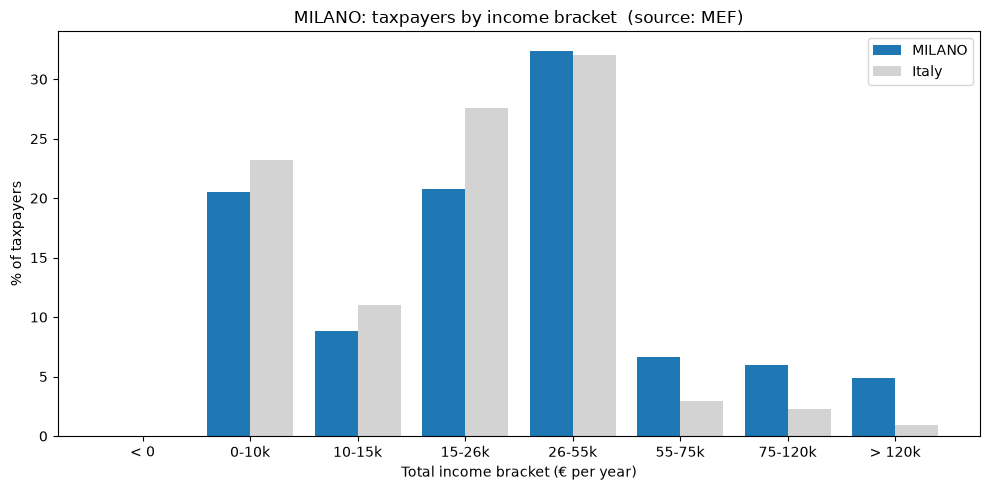

In [56]:
plot_income_brackets(mef_dfs[2024], "015146")
plt.show()

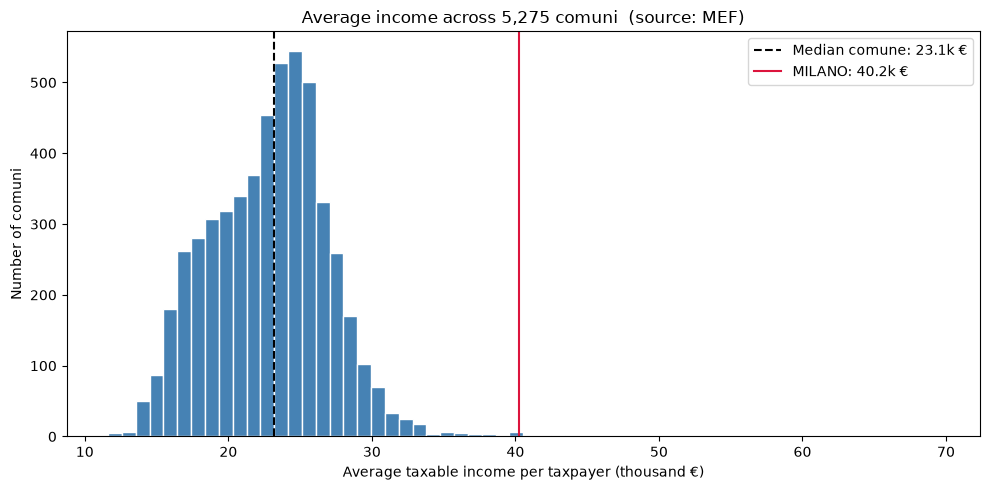

In [57]:
plot_mean_income_histogram(mef_dfs[2024], highlight="MILANO", min_taxpayers=1000)
plt.show()

Ideas to look at with these charts:
 - Compare a rich city (Milano), a southern city (Napoli) and a mountain village.
 - Where is the pensioner share much higher than in Italy?
 - Does the 2014 histogram look shifted compared with 2024? (Remember: nominal euros.)